# Case iFood — Estratégia de Campanha de Marketing

## Objetivo
Recomendar uma estratégia data-driven para melhorar a rentabilidade da próxima campanha de marketing, selecionando os clientes com maior probabilidade de conversão.

##Fase 1 — Tratamento e Limpeza dos Dados

In [0]:
# Importações
import pandas as pd
import numpy as np

# Carregar os dados da tabela do Databricks
df = spark.table("ifood_case_data").toPandas()

# Conferir dimensões
print(f"Linhas: {df.shape[0]}, Colunas: {df.shape[1]}")

Linhas: 2240, Colunas: 29


In [0]:
# 1.1 — Year_Birth: imputar 3 valores inválidos com a mediana
# Justificativa: 3 clientes com ano de nascimento < 1940 (dados claramente inválidos). Em vez de excluir (perderíamos o cliente da análise de targeting),
# imputamos a mediana de Year_Birth — mesma lógica usada para Income nulo.

mediana_birth = df.loc[df['Year_Birth'] >= 1940, 'Year_Birth'].median()
print(f"Mediana Year_Birth: {mediana_birth}")
print(f"Valores inválidos antes:")
print(df[df['Year_Birth'] < 1940][['ID', 'Year_Birth']])

df.loc[df['Year_Birth'] < 1940, 'Year_Birth'] = mediana_birth

print(f"\nLinhas mantidas: {df.shape[0]}")
print(f"Mínimo Year_Birth agora: {df['Year_Birth'].min()}")

Mediana Year_Birth: 1970.0
Valores inválidos antes:
        ID  Year_Birth
192   7829        1900
239  11004        1893
339   1150        1899

Linhas mantidas: 2240
Mínimo Year_Birth agora: 1940


In [0]:
### 1.2 — Income nulo: imputar com mediana
## 24 linhas sem renda. Mediana (51.373) é mais robusta que a média por causa do outlier extremo.

mediana_income = df['Income'].median()
print(f"Mediana de Income: {mediana_income}")
print(f"Nulos antes: {df['Income'].isnull().sum()}")

df['Income'] = df['Income'].fillna(mediana_income)

print(f"Nulos depois: {df['Income'].isnull().sum()}")

Mediana de Income: 51381.5
Nulos antes: 24
Nulos depois: 0


In [0]:
### 1.3 — Income outlier: capar no percentil 99
### 1 cliente com renda de 666.666 (13x a mediana). Capping preserva o cliente mas reduz a distorção.

print(f"Income max antes: {df['Income'].max()}")
p99 = df['Income'].quantile(0.99)
df.loc[df['Income'] > p99, 'Income'] = p99
print(f"Income max depois: {df['Income'].max()}")

Income max antes: 666666.0
Income max depois: 94437.68000000001


In [0]:
### 1.4 — Marital_Status: reagrupar valores atípicos
# "Absurd" (2), "YOLO" (2) e "Alone" (3) não são categorias reais. "Alone" , "Absurd" e "YOLO" → "Other".

print("Antes:")
print(df['Marital_Status'].value_counts())

df.loc[df['Marital_Status'].isin(['Absurd', 'YOLO', 'Alone']), 'Marital_Status'] = 'Other'

print("\nDepois:")
print(df['Marital_Status'].value_counts())

Antes:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

Depois:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Other         7
Name: count, dtype: int64


In [0]:
# 1.5 — Separar parâmetros financeiros e remover das features
# Z_CostContact = 3 (custo por contato) e Z_Revenue = 11 (receita por conversão)
# São constantes: não discriminam clientes. Guardamos como variáveis
# para o cálculo financeiro e removemos do DataFrame de análise.

COST_PER_CONTACT = 3
REVENUE_PER_CONVERSION = 11

df = df.drop(columns=['Z_CostContact', 'Z_Revenue'])
print(f"Colunas restantes: {df.shape[1]}")
print(f"Custo por contato: {COST_PER_CONTACT} MU")
print(f"Receita por conversão: {REVENUE_PER_CONVERSION} MU")

Colunas restantes: 27
Custo por contato: 3 MU
Receita por conversão: 11 MU


In [0]:
# 1.6 — Feature Engineering
# Premissa: usamos a data maxima de cadastro (Dt_Customer.max()) como referencia aproximada, pois nao temos a data exata da campanha piloto.
# A campanha ocorreu apos o ultimo cadastro, mas o intervalo exato e desconhecido. Para idade e tempo de cadastro, esta aproximacao e suficiente.

data_ref = df['Dt_Customer'].max()
print(f"Data de referencia: {data_ref.date()}")

# Idade do cliente
df['Age'] = data_ref.year - df['Year_Birth']

# Tempo de cadastro em meses
df['Months_Enrolled'] = ((data_ref - df['Dt_Customer']).dt.days / 30).round(1)

# Total gasto nos últimos 2 anos
df['Total_Spent'] = df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] + \
                    df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds']

# Total de campanhas aceitas
df['Total_Accepted_Cmps'] = df['AcceptedCmp1'] + df['AcceptedCmp2'] + \
                            df['AcceptedCmp3'] + df['AcceptedCmp4'] + df['AcceptedCmp5']

# Total de filhos
df['Total_Kids'] = df['Kidhome'] + df['Teenhome']

# Total de compras
df['Total_Purchases'] = df['NumWebPurchases'] + df['NumCatalogPurchases'] + df['NumStorePurchases']

print("Novas colunas:")
print(df[['Age', 'Months_Enrolled', 'Total_Spent', 'Total_Accepted_Cmps', 
         'Total_Kids', 'Total_Purchases']].describe().to_string())

Data de referencia: 2014-06-29
Novas colunas:
               Age  Months_Enrolled  Total_Spent  Total_Accepted_Cmps   Total_Kids  Total_Purchases
count  2240.000000      2240.000000  2240.000000          2240.000000  2240.000000      2240.000000
mean     45.096875        11.786116   605.798214             0.297768     0.950446        12.537054
std      11.694144         6.737160   602.249288             0.678381     0.751803         7.205741
min      18.000000         0.000000     5.000000             0.000000     0.000000         0.000000
25%      37.000000         6.000000    68.750000             0.000000     0.000000         6.000000
50%      44.000000        11.850000   396.000000             0.000000     1.000000        12.000000
75%      55.000000        17.600000  1045.500000             0.000000     1.000000        18.000000
max      74.000000        23.300000  2525.000000             4.000000     3.000000        32.000000


## Fase 2 — Análise Exploratória

Objetivo: identificar quais características dos clientes mais se relacionam com a probabilidade de compra (Response) para orientar a estratégia de targeting.

In [0]:
# ============================================================
# PERFIL: CONVERTEU vs NÃO CONVERTEU NA CAMPANHA PILOTO
# ============================================================
# Response = 1: comprou na campanha piloto (334 clientes)
# Response = 0: não comprou na campanha piloto (1906 clientes)
# ============================================================

variaveis_numericas = df.select_dtypes(include=['number']).columns.drop(['ID', 'Response'])

comparacao = pd.DataFrame({
    'Média (Converteu)': conv[variaveis_numericas].mean(),
    'Média (Não Converteu)': nao_conv[variaveis_numericas].mean()
})
comparacao['Diferença'] = comparacao['Média (Converteu)'] - comparacao['Média (Não Converteu)']
comparacao['Diferença %'] = (comparacao['Diferença'] / comparacao['Média (Não Converteu)'].abs()) * 100

# Separar binárias de contínuas
binarias = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Complain']
comparacao_bin = comparacao.loc[comparacao.index.isin(binarias)].sort_values('Diferença %', ascending=False)
comparacao_cont = comparacao.loc[~comparacao.index.isin(binarias)].sort_values('Diferença %', ascending=False)

# Binárias: 1 casa decimal (são proporções)
comparacao_bin = comparacao_bin.round(4)

# Contínuas: 4 casas decimais
comparacao_cont = comparacao_cont.round(2)

print("=" * 70)
print("PERFIL: CONVERTEU (Response=1) vs NÃO CONVERTEU (Response=0)")
print("Campanha piloto: 2.240 clientes | 334 converteram | 1.906 não converteram")
print("=" * 70)

print()
print(">>> VARIÁVEIS BINÁRIAS (campanhas anteriores e reclamação) <<<")
print("A média representa o % de clientes que aceitou aquela campanha")
print("Ex: AcceptedCmp5 = 0,276 → 27,6% dos conversores aceitaram a Camp.5")
print("-" * 70)
print(comparacao_bin.to_string())

print()
print(">>> VARIÁVEIS CONTÍNUAS (perfil e comportamento de compra) <<<")
print("A média representa o valor médio da variável")
print("Ex: Income = 60052.0342 → renda média de 60.052,0342 MU")
print("-" * 70)
print(comparacao_cont.to_string())

PERFIL: CONVERTEU (Response=1) vs NÃO CONVERTEU (Response=0)
Campanha piloto: 2.240 clientes | 334 converteram | 1.906 não converteram

>>> VARIÁVEIS BINÁRIAS (campanhas anteriores e reclamação) <<<
A média representa o % de clientes que aceitou aquela campanha
Ex: AcceptedCmp5 = 0,276 → 27,6% dos conversores aceitaram a Camp.5
----------------------------------------------------------------------
              Média (Converteu)  Média (Não Converteu)  Diferença  Diferença %
AcceptedCmp2             0.0599                 0.0052     0.0546    1041.3174
AcceptedCmp5             0.2754                 0.0373     0.2382     639.4451
AcceptedCmp1             0.2365                 0.0341     0.2024     593.5698
AcceptedCmp3             0.2305                 0.0451     0.1854     410.9386
AcceptedCmp4             0.1856                 0.0551     0.1305     236.9604
Complain                 0.0090                 0.0094    -0.0005      -4.8902

>>> VARIÁVEIS CONTÍNUAS (perfil e comportamen

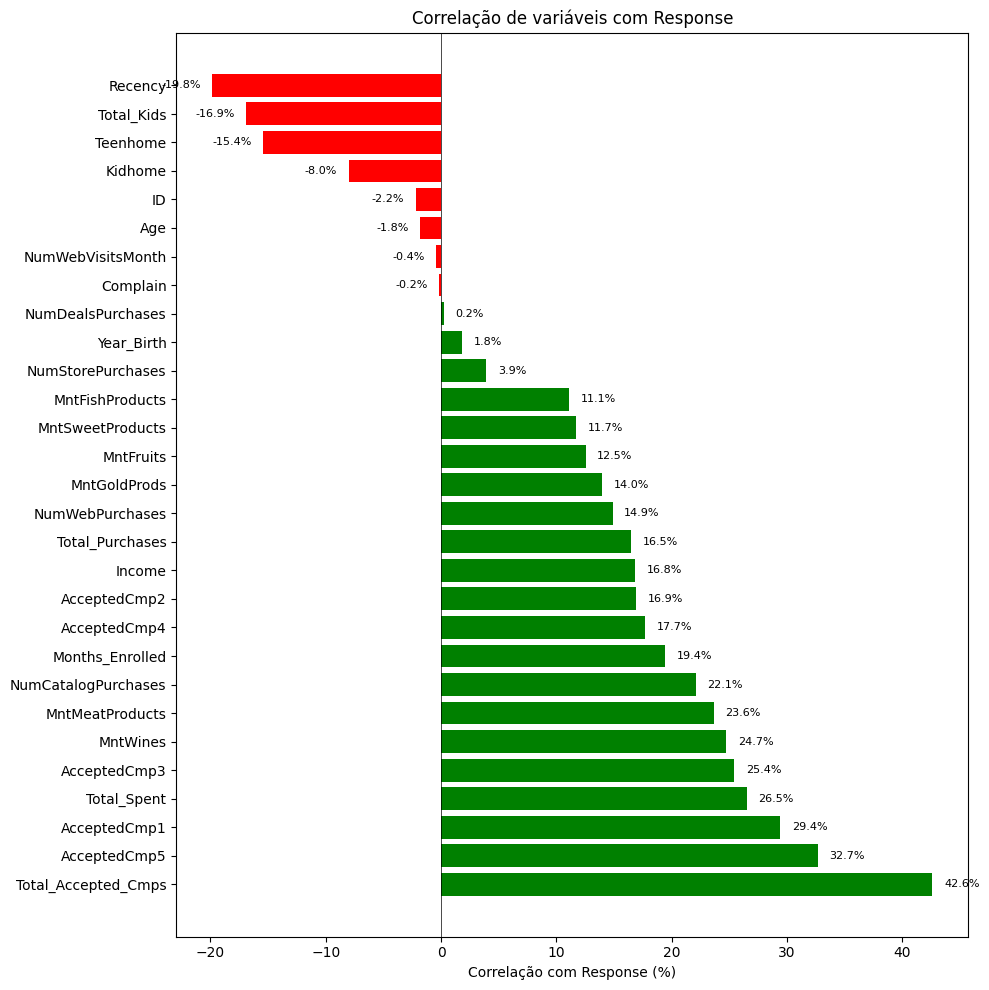

In [0]:
### 2.1 — Correlação geral com Response
#Ranking de todas as variáveis numéricas em relação à resposta da campanha piloto.

import matplotlib.pyplot as plt

# Correlação de todas as numéricas com Response, ordenada (exclui a própria Response)
corr_response = df.select_dtypes(include=['number']).corr()['Response'].drop('Response').sort_values(ascending=False)

plt.figure(figsize=(10, 10))
colors = ['green' if x > 0 else 'red' for x in corr_response.values]
bars = plt.barh(corr_response.index, corr_response.values * 100, color=colors)

# Anotar o valor em porcentagem em cada barra
for bar, val in zip(bars, corr_response.values):
    x = bar.get_width()
    plt.text(x + (1 if x >= 0 else -1), bar.get_y() + bar.get_height()/2,
             f"{val*100:.1f}%", va='center', 
             ha='left' if x >= 0 else 'right', fontsize=8)

plt.xlabel('Correlação com Response (%)')
plt.title('Correlação de variáveis com Response')
plt.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

 Total_Accepted_Cmps  total_clientes  conversoes  taxa_conversao
                   0            1777         146             8.2
                   1             325         101            31.1
                   2              83          42            50.6
                   3              44          35            79.5
                   4              11          10            90.9


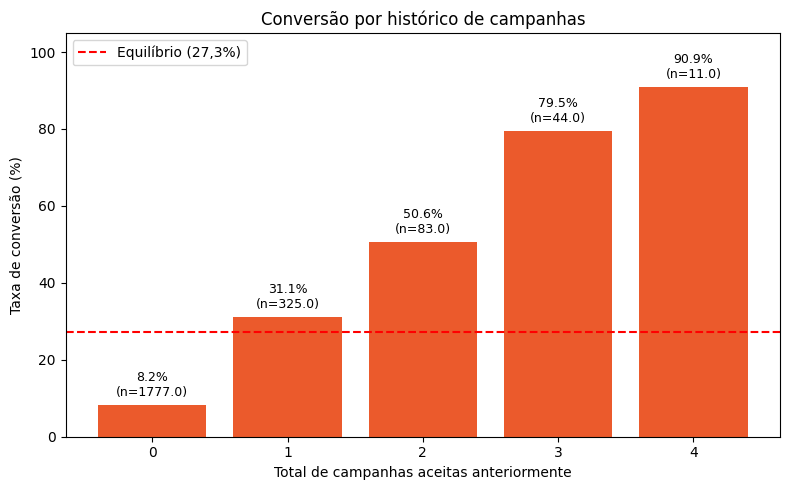

In [0]:
### 2.2 — Histórico de campanhas vs Response
## Cliente que aceitou campanhas anteriores tem maior probabilidade de compra?

# Tabela: taxa de conversão por total de campanhas aceitas
cmp_table = df.groupby('Total_Accepted_Cmps').agg(
    total_clientes=('Response', 'count'),
    conversoes=('Response', 'sum'),
    taxa_conversao=('Response', 'mean')
).reset_index()
cmp_table['taxa_conversao'] = (cmp_table['taxa_conversao'] * 100).round(1)
print(cmp_table.to_string(index=False))

# Gráfico de barras
plt.figure(figsize=(8, 5))
bars = plt.bar(cmp_table['Total_Accepted_Cmps'].astype(str), cmp_table['taxa_conversao'], color='#eb5a2c')

# Anotar taxa de conversão e número de clientes em cada barra
for bar, (_, row) in zip(bars, cmp_table.iterrows()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
             f"{row['taxa_conversao']:.1f}%\n(n={row['total_clientes']})",
             ha='center', va='bottom', fontsize=9)

plt.axhline(y=27.3, color='red', linestyle='--', label='Equilíbrio (27,3%)')
plt.xlabel('Total de campanhas aceitas anteriormente')
plt.ylabel('Taxa de conversão (%)')
plt.title('Conversão por histórico de campanhas')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

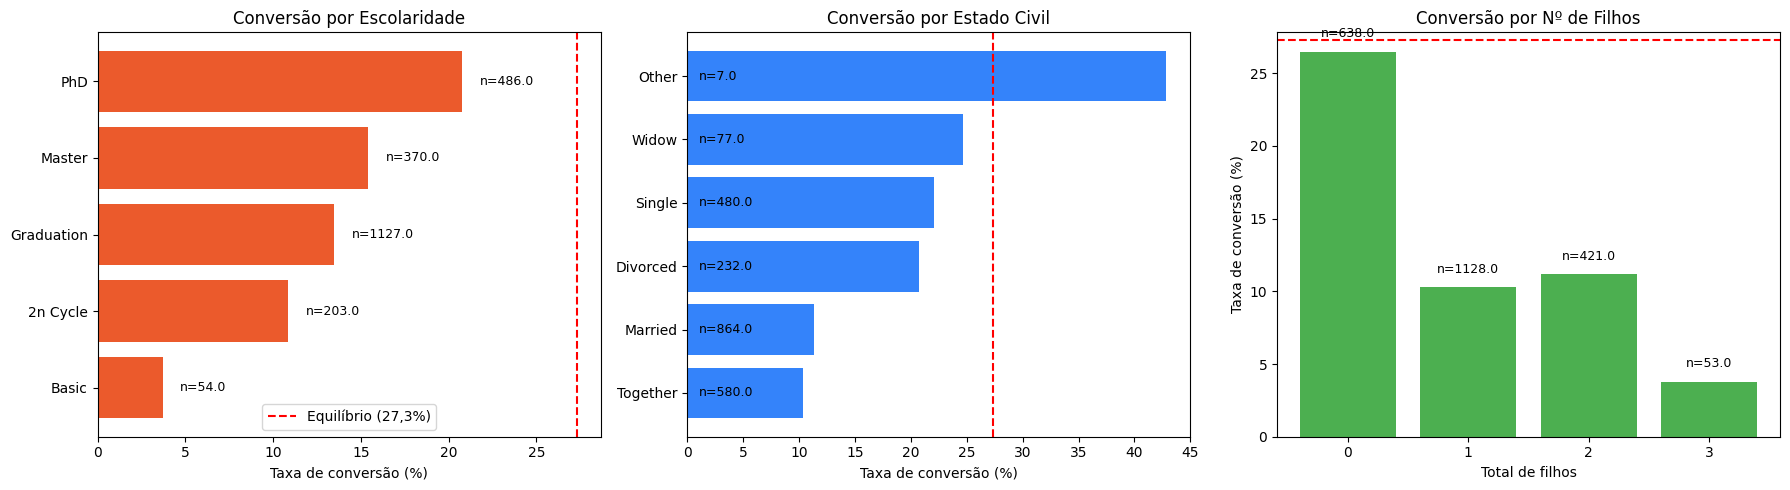

In [0]:
### 2.3 — Perfil demográfico vs Response
#Escolaridade, estado civil e filhos influenciam a conversão?

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Education — barra = taxa de conversão, rótulo = nº de clientes
edu = df.groupby('Education').agg(
    taxa=('Response', 'mean'),
    n=('Response', 'count')
).sort_values('taxa', ascending=True)
axes[0].barh(edu.index, edu['taxa'] * 100, color='#eb5a2c')
axes[0].axvline(x=27.3, color='red', linestyle='--', label='Equilíbrio (27,3%)')
for i, (idx, row) in enumerate(edu.iterrows()):
    axes[0].text(row['taxa'] * 100 + 1, i, f"n={row['n']}", va='center', fontsize=9)
axes[0].set_xlabel('Taxa de conversão (%)')
axes[0].set_title('Conversão por Escolaridade')
axes[0].legend()

# Marital_Status
ms = df.groupby('Marital_Status').agg(
    taxa=('Response', 'mean'),
    n=('Response', 'count')
).sort_values('taxa', ascending=True)
axes[1].barh(ms.index, ms['taxa'] * 100, color='#3483fa')
axes[1].axvline(x=27.3, color='red', linestyle='--')
for i, (idx, row) in enumerate(ms.iterrows()):
    axes[1].text(row['taxa'] * 0 + 1, i, f"n={row['n']}", va='center', fontsize=9)
axes[1].set_xlabel('Taxa de conversão (%)')
axes[1].set_title('Conversão por Estado Civil')

# Total_Kids
kids = df.groupby('Total_Kids').agg(
    taxa=('Response', 'mean'),
    n=('Response', 'count')
)
axes[2].bar(kids.index.astype(str), kids['taxa'] * 100, color='#4caf50')
axes[2].axhline(y=27.3, color='red', linestyle='--')
for i, (idx, row) in enumerate(kids.iterrows()):
    axes[2].text(i, row['taxa'] * 100 + 1, f"n={row['n']}", ha='center', fontsize=9)
axes[2].set_xlabel('Total de filhos')
axes[2].set_ylabel('Taxa de conversão (%)')
axes[2].set_title('Conversão por Nº de Filhos')

plt.tight_layout()
plt.show()

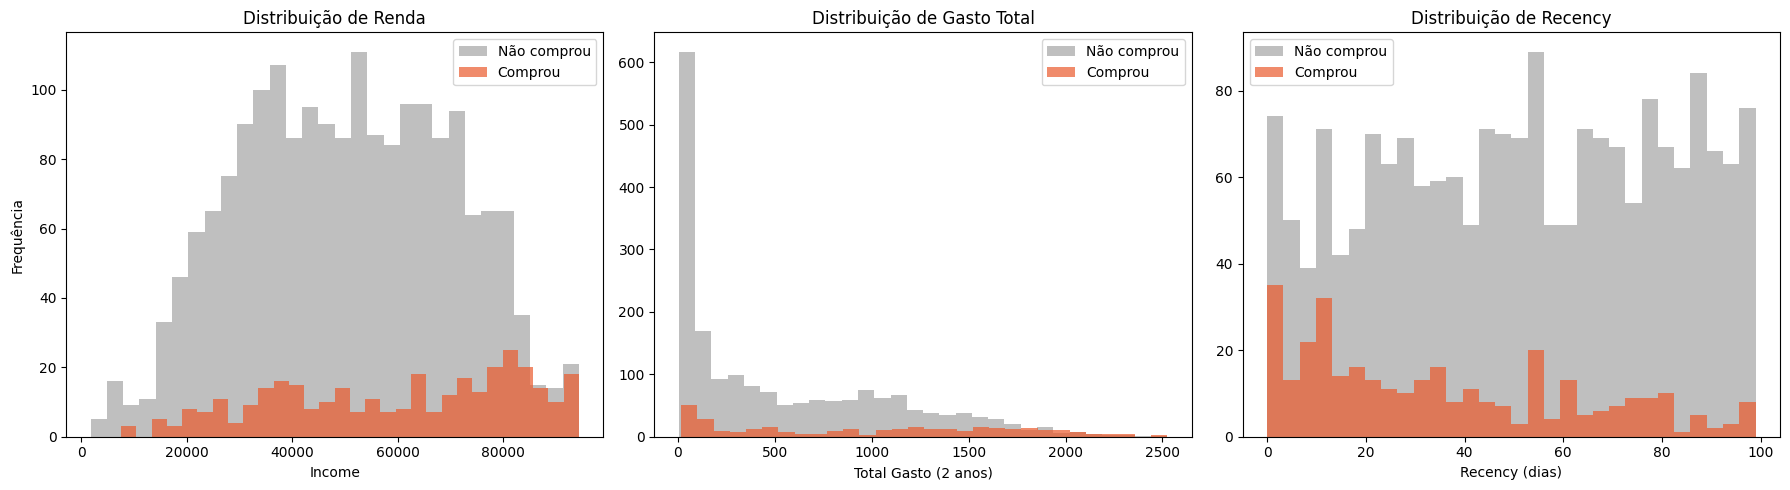

In [0]:
### 2.4 — Comportamento de compra vs Response
#Renda, gasto total e recency influenciam a conversão?
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Income
axes[0].hist(df[df['Response']==0]['Income'], bins=30, alpha=0.5, label='Não comprou', color='gray')
axes[0].hist(df[df['Response']==1]['Income'], bins=30, alpha=0.7, label='Comprou', color='#eb5a2c')
axes[0].set_xlabel('Income')
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição de Renda')
axes[0].legend()

# Total_Spent
axes[1].hist(df[df['Response']==0]['Total_Spent'], bins=30, alpha=0.5, label='Não comprou', color='gray')
axes[1].hist(df[df['Response']==1]['Total_Spent'], bins=30, alpha=0.7, label='Comprou', color='#eb5a2c')
axes[1].set_xlabel('Total Gasto (2 anos)')
axes[1].set_title('Distribuição de Gasto Total')
axes[1].legend()

# Recency
axes[2].hist(df[df['Response']==0]['Recency'], bins=30, alpha=0.5, label='Não comprou', color='gray')
axes[2].hist(df[df['Response']==1]['Recency'], bins=30, alpha=0.7, label='Comprou', color='#eb5a2c')
axes[2].set_xlabel('Recency (dias)')
axes[2].set_title('Distribuição de Recency')
axes[2].legend()

plt.tight_layout()
plt.show()

### Insights da Análise Exploratória

1. **Histórico de campanhas é o preditor mais forte** (correlação +0,43). Clientes que aceitaram 1+ campanhas anteriores têm taxa de conversão de 31-91%, vs 8,2% para quem nunca aceitou.

2. **Gasto total e renda** se relacionam positivamente (correlação +0,27 e +0,17). Clientes que gastam mais e têm maior renda convertem mais.

3. **Recency é negativo** (correlação -0,20). Quanto mais tempo sem comprar, menor a probabilidade de conversão.

4. **Filhos reduzem conversão** (correlação -0,17). Clientes sem filhos convertem mais que clientes com filhos.

5. **Escolaridade**: PhD (20,8%) e Master (15,4%) convertem mais que Basic (3,7%).

6. **Estado civil**: Single (22,1%) e Divorced (20,7%) convertem quase 2x mais que Married (11,3%) e Together (10,3%).

**Conclusão da EDA**: o histórico de aceitação de campanhas anteriores é o principal sinal. Combinado com gasto, renda e recency, forma a base da estratégia de targeting.

## Fase 3 — Estratégia de Targeting

### Premissas financeiras
- Custo por contato: 3 MU
- Receita por conversão: 11 MU
- Ponto de equilíbrio: 3 / 11 = 27,3% (taxa de conversão mínima para lucro)
- Piloto: 2.240 clientes, taxa 14,9%, lucro -3.046 MU

### Hipótese
Clientes que aceitaram campanhas anteriores (Total_Accepted_Cmps >= 1)
têm taxa de conversão acima do ponto de equilíbrio. Se a hipótese for
verdadeira, contactar apenas esse grupo deve gerar lucro.

In [0]:
COST_PER_CONTACT = 3
REVENUE_PER_CONVERSION = 11

def calcular_cenario(nome, grupo):
    n = len(grupo)
    conv = int(grupo['Response'].sum())
    taxa = grupo['Response'].mean() * 100
    custo = n * COST_PER_CONTACT
    receita = conv * REVENUE_PER_CONVERSION
    lucro = receita - custo
    rentabilidade = ((receita - custo) / custo * 100) if custo > 0 else 0
    print(f"{nome}")
    print(f"  Clientes: {n} | Conversões: {conv} | Taxa: {taxa:.1f}%")
    print(f"  Custo: {custo} | Receita: {receita} | Lucro: {lucro} | Rentabilidade: {rentabilidade:.1f}%")
    print(f"  Taxa de conversão acima do equilíbrio (27,3%)? {'SIM' if taxa > 27.3 else 'NAO'}")
    print()
    return {'cenario': nome, 'n': n, 'conv': conv, 'taxa': round(taxa,1),
            'custo': custo, 'receita': receita, 'lucro': lucro,
            'rentabilidade': round(rentabilidade,1)}

# Piloto (todos os clientes)
r0 = calcular_cenario("PILOTO (todos)", df)

# Cenários individuais
r1 = calcular_cenario("C1: Total_Accepted_Cmps >= 1", df[df['Total_Accepted_Cmps'] >= 1])
r2 = calcular_cenario("C2: AcceptedCmp5 == 1", df[df['AcceptedCmp5'] == 1])
r3 = calcular_cenario("C3: AcceptedCmp1 == 1", df[df['AcceptedCmp1'] == 1])
r4 = calcular_cenario("C4: AcceptedCmp3 == 1", df[df['AcceptedCmp3'] == 1])

mediana_spent = df['Total_Spent'].median()
r5 = calcular_cenario(f"C5: Total_Spent > mediana ({mediana_spent})", 
                       df[df['Total_Spent'] > mediana_spent])

print("=== TABELA COMPARATIVA ===")
resultados = [r0, r1, r2, r3, r4, r5]
resultados_df = pd.DataFrame(resultados)
resultados_df = resultados_df.sort_values('lucro', ascending=False)
print(resultados_df.to_string(index=False))

PILOTO (todos)
  Clientes: 2240 | Conversões: 334 | Taxa: 14.9%
  Custo: 6720 | Receita: 3674 | Lucro: -3046 | Rentabilidade: -45.3%
  Taxa de conversão acima do equilíbrio (27,3%)? NAO

C1: Total_Accepted_Cmps >= 1
  Clientes: 463 | Conversões: 188 | Taxa: 40.6%
  Custo: 1389 | Receita: 2068 | Lucro: 679 | Rentabilidade: 48.9%
  Taxa de conversão acima do equilíbrio (27,3%)? SIM

C2: AcceptedCmp5 == 1
  Clientes: 163 | Conversões: 92 | Taxa: 56.4%
  Custo: 489 | Receita: 1012 | Lucro: 523 | Rentabilidade: 107.0%
  Taxa de conversão acima do equilíbrio (27,3%)? SIM

C3: AcceptedCmp1 == 1
  Clientes: 144 | Conversões: 79 | Taxa: 54.9%
  Custo: 432 | Receita: 869 | Lucro: 437 | Rentabilidade: 101.2%
  Taxa de conversão acima do equilíbrio (27,3%)? SIM

C4: AcceptedCmp3 == 1
  Clientes: 163 | Conversões: 77 | Taxa: 47.2%
  Custo: 489 | Receita: 847 | Lucro: 358 | Rentabilidade: 73.2%
  Taxa de conversão acima do equilíbrio (27,3%)? SIM

C5: Total_Spent > mediana (396.0)
  Clientes: 1119 |

## Fase 4 — Machine Learning (Validação)

### Objetivo
Usar regressão logística como análise multivariada para validar a estratégia
por regras. O modelo considera todas as variáveis simultaneamente e pontua
cada cliente com uma probabilidade de conversão.

In [0]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Preparar dados: remover colunas que não entram no modelo
# ID: identificador | Year_Birth: já temos Age | Dt_Customer: já temos Months_Enrolled
# Response: é o alvo (não pode entrar como feature)
df_ml = df.drop(columns=['ID', 'Year_Birth', 'Dt_Customer', 'Response'])

# One-hot encoding: converter Education e Marital_Status em colunas binárias
# drop_first=True evita multicolinearidade (uma categoria vira referência)
df_ml = pd.get_dummies(df_ml, columns=['Education', 'Marital_Status'], drop_first=True)

X = df_ml
y = df['Response']

print(f"Features: {X.shape[1]} colunas")
print(f"Linhas: {X.shape[0]}")
print(f"Colunas: {list(X.columns)}")

# Padronizar variáveis (média=0, desvio=1) — necessário para regressão logística
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Treinar modelo
modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_scaled, y)

print("Modelo treinado com sucesso!")

Features: 36 colunas
Linhas: 2240
Colunas: ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Age', 'Months_Enrolled', 'Total_Spent', 'Total_Accepted_Cmps', 'Total_Kids', 'Total_Purchases', 'Education_Basic', 'Education_Graduation', 'Education_Master', 'Education_PhD', 'Marital_Status_Married', 'Marital_Status_Other', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow']
Modelo treinado com sucesso!


In [0]:
# Pontuar cada cliente com probabilidade de conversão (0 a 100%)
df['probabilidade'] = modelo.predict_proba(X_scaled)[:, 1]

# Ordenar do mais provável para o menos provável
df_sorted = df.sort_values('probabilidade', ascending=False).reset_index(drop=True)

# Calcular lucro cumulativo: para cada N clientes do topo, quanto seria o lucro?
cum_conv = df_sorted['Response'].cumsum()
n_clientes = range(1, len(df_sorted) + 1)
lucro_cum = cum_conv * REVENUE_PER_CONVERSION - pd.Series(n_clientes) * COST_PER_CONTACT

# Encontrar o N que maximiza o lucro
melhor_n = lucro_cum.idxmax() + 1
melhor_lucro = int(lucro_cum.iloc[melhor_n - 1])
conv_ml = int(cum_conv.iloc[melhor_n - 1])
taxa_ml = conv_ml / melhor_n * 100
custo_ml = melhor_n * COST_PER_CONTACT
receita_ml = conv_ml * REVENUE_PER_CONVERSION
roi_ml = (receita_ml - custo_ml) / custo_ml * 100

print(f"=== MELHOR LIMIAR DO MODELO ===")
print(f"Contactar os top {melhor_n} clientes (probabilidade mais alta)")
print(f"Conversões esperadas: {conv_ml}")
print(f"Taxa de conversão: {taxa_ml:.1f}%")
print(f"Custo: {custo_ml} MU | Receita: {receita_ml} MU")
print(f"Lucro: {melhor_lucro} MU | ROI: {roi_ml:.1f}%")

=== MELHOR LIMIAR DO MODELO ===
Contactar os top 425 clientes (probabilidade mais alta)
Conversões esperadas: 240
Taxa de conversão: 56.5%
Custo: 1275 MU | Receita: 2640 MU
Lucro: 1365 MU | ROI: 107.1%


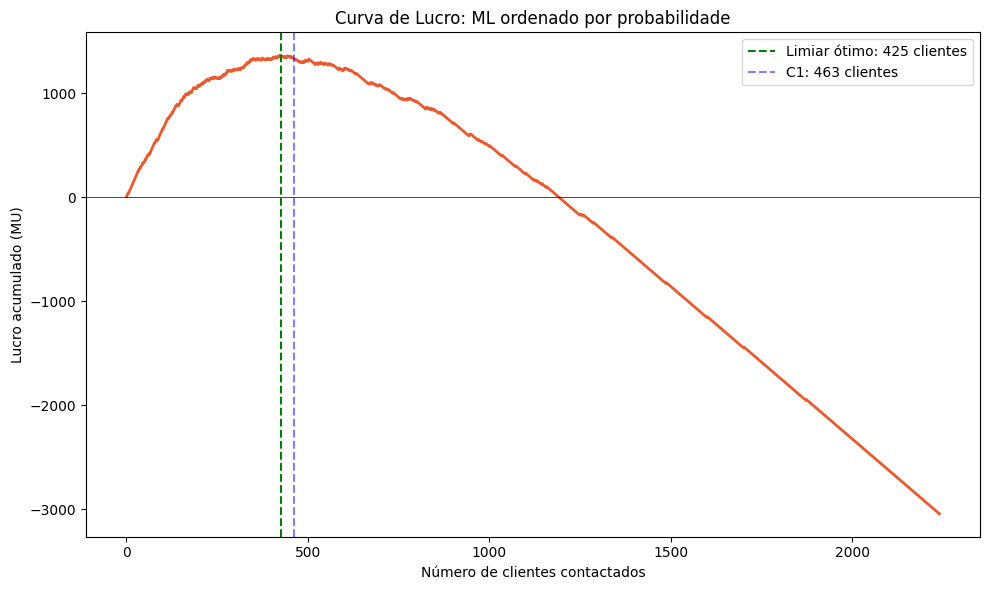

In [0]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(df_sorted) + 1), lucro_cum.values, color='#eb5a2c', linewidth=2)
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
plt.axvline(x=melhor_n, color='green', linestyle='--', label=f'Limiar ótimo: {melhor_n} clientes')
plt.axvline(x=463, color='blue', linestyle='--', alpha=0.5, label='C1: 463 clientes')
plt.xlabel('Número de clientes contactados')
plt.ylabel('Lucro acumulado (MU)')
plt.title('Curva de Lucro: ML ordenado por probabilidade')
plt.legend()
plt.tight_layout()
plt.show()

=== ML OTIMIZADO POR RENTABILIDADE ===
Contactar os top 52 clientes
Conversões: 47 | Taxa: 90.4%
Custo: 156 | Receita: 517
Lucro: 361 | Rentabilidade: 231.4%


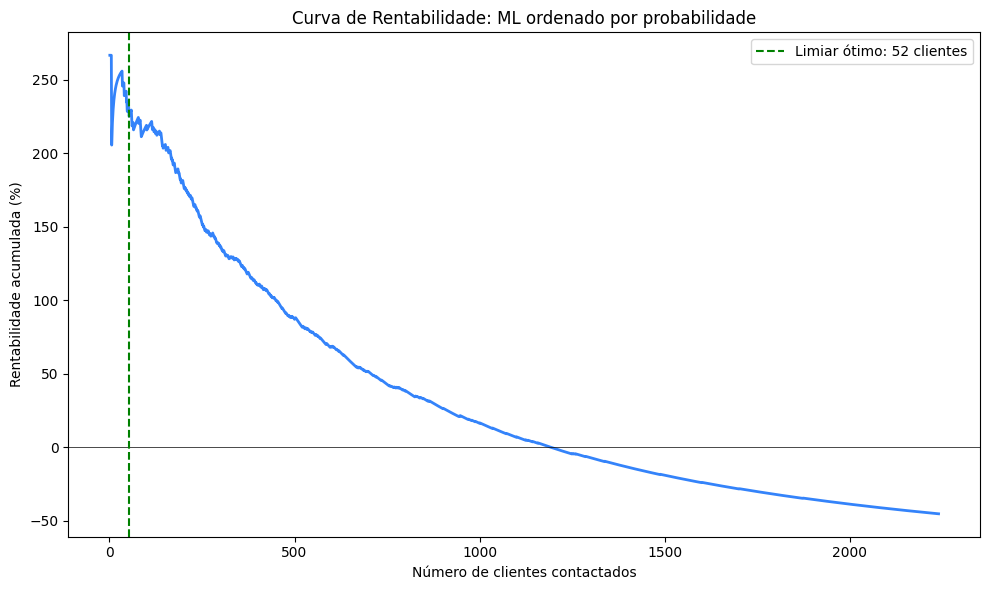

In [0]:
# Calcular rentabilidade cumulativa
cum_conv_ml = df_sorted['Response'].cumsum()
n_vals_ml = range(1, len(df_sorted) + 1)
rentab_cum = (cum_conv_ml * REVENUE_PER_CONVERSION - pd.Series(n_vals_ml) * COST_PER_CONTACT) / (pd.Series(n_vals_ml) * COST_PER_CONTACT) * 100

# Encontrar N que maximiza a rentabilidade (mínimo de 50 clientes)
rentab_filtrada = rentab_cum.copy()
rentab_filtrada.iloc[:49] = -9999
melhor_n_rentab = rentab_filtrada.idxmax() + 1

conv_rentab = int(cum_conv_ml.iloc[melhor_n_rentab - 1])
taxa_rentab = conv_rentab / melhor_n_rentab * 100
custo_rentab = melhor_n_rentab * COST_PER_CONTACT
receita_rentab = conv_rentab * REVENUE_PER_CONVERSION
lucro_rentab = receita_rentab - custo_rentab
rentab_final = lucro_rentab / custo_rentab * 100

print(f"=== ML OTIMIZADO POR RENTABILIDADE ===")
print(f"Contactar os top {melhor_n_rentab} clientes")
print(f"Conversões: {conv_rentab} | Taxa: {taxa_rentab:.1f}%")
print(f"Custo: {custo_rentab} | Receita: {receita_rentab}")
print(f"Lucro: {lucro_rentab} | Rentabilidade: {rentab_final:.1f}%")

# Gráfico da curva de rentabilidade
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(df_sorted) + 1), rentab_cum.values, color='#3483fa', linewidth=2)
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
plt.axvline(x=melhor_n_rentab, color='green', linestyle='--', label=f'Limiar ótimo: {melhor_n_rentab} clientes')
plt.xlabel('Número de clientes contactados')
plt.ylabel('Rentabilidade acumulada (%)')
plt.title('Curva de Rentabilidade: ML ordenado por probabilidade')
plt.legend()
plt.tight_layout()
plt.show()

=== ML EQUILIBRIO (lucro + rentabilidade) ===
Contactar os top 164 clientes
Conversões: 135 | Taxa: 82.3%
Custo: 492 | Receita: 1485
Lucro: 993 | Rentabilidade: 201.8%
Equivalente a 73% do lucro maximo e 76% da rentabilidade maxima


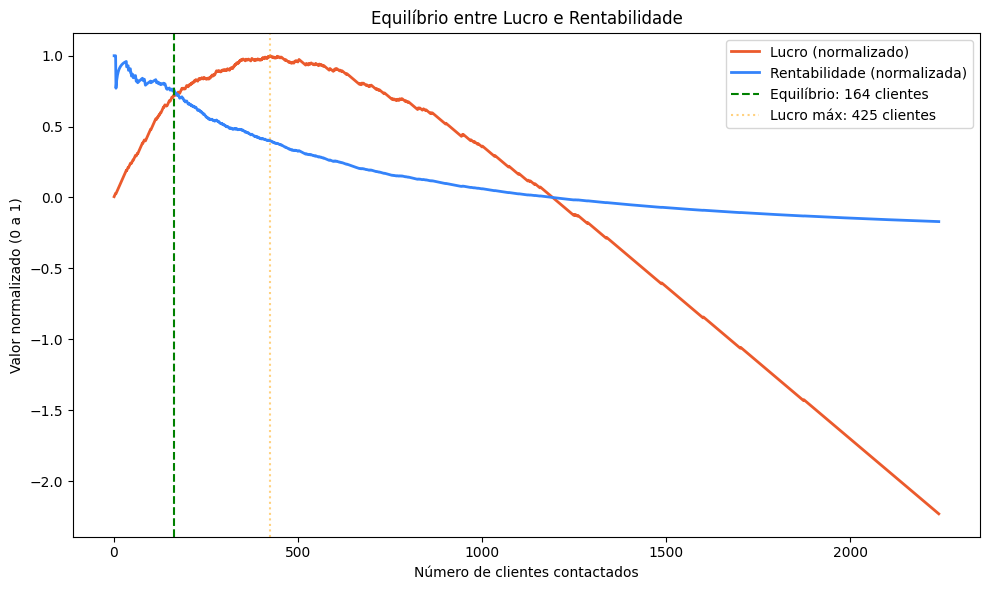

In [0]:
# Normalizar as duas curvas para 0-1
lucro_norm = lucro_cum / lucro_cum.max()
rentab_cum = (cum_conv_ml * REVENUE_PER_CONVERSION - pd.Series(n_vals_ml) * COST_PER_CONTACT) / (pd.Series(n_vals_ml) * COST_PER_CONTACT) * 100
rentab_norm = rentab_cum / rentab_cum.max()

# Produto das curvas normalizadas = onde ambas sao altas ao mesmo tempo
produto = lucro_norm * rentab_norm
produto.iloc[:49] = 0  # minimo de 50 clientes
eq_idx = produto.idxmax()
n_equilibrio = eq_idx + 1

conv_eq = int(cum_conv_ml.iloc[eq_idx])
taxa_eq = conv_eq / n_equilibrio * 100
custo_eq = n_equilibrio * COST_PER_CONTACT
receita_eq = conv_eq * REVENUE_PER_CONVERSION
lucro_eq = receita_eq - custo_eq
rentab_eq = lucro_eq / custo_eq * 100

print(f"=== ML EQUILIBRIO (lucro + rentabilidade) ===")
print(f"Contactar os top {n_equilibrio} clientes")
print(f"Conversões: {conv_eq} | Taxa: {taxa_eq:.1f}%")
print(f"Custo: {custo_eq} | Receita: {receita_eq}")
print(f"Lucro: {lucro_eq} | Rentabilidade: {rentab_eq:.1f}%")
print(f"Equivalente a {lucro_eq/lucro_cum.max()*100:.0f}% do lucro maximo e {rentab_eq/rentab_cum.max()*100:.0f}% da rentabilidade maxima")

# Gráfico com as duas curvas normalizadas
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(df_sorted) + 1), lucro_norm.values, color='#eb5a2c', linewidth=2, label='Lucro (normalizado)')
plt.plot(range(1, len(df_sorted) + 1), rentab_norm.values, color='#3483fa', linewidth=2, label='Rentabilidade (normalizada)')
plt.axvline(x=n_equilibrio, color='green', linestyle='--', label=f'Equilíbrio: {n_equilibrio} clientes')
plt.axvline(x=melhor_n, color='orange', linestyle=':', alpha=0.5, label=f'Lucro máx: {melhor_n} clientes')
plt.xlabel('Número de clientes contactados')
plt.ylabel('Valor normalizado (0 a 1)')
plt.title('Equilíbrio entre Lucro e Rentabilidade')
plt.legend()
plt.tight_layout()
plt.show()

### Perfil dos clientes selecionados pelo ML (3 cenários)
Comparação do perfil dos clientes selecionados em cada cenário ML
com o restante da base, para entender quem o modelo escolheu.

In [0]:
def perfil_ml(nome, grupo_selecionado, grupo_restante):
    print(f"\n{'='*65}")
    print(f"PERFIL: {nome}")
    print(f"Selecionados: {len(grupo_selecionado)} | Restante: {len(grupo_restante)}")
    print(f"{'='*65}")
    
    # Variáveis contínuas
    variaveis_num = ['Income', 'Recency', 'Total_Spent', 'MntWines', 'MntMeatProducts',
                     'NumCatalogPurchases', 'Total_Accepted_Cmps', 'Total_Kids', 'Months_Enrolled', 'Age']
    
    print("\n>>> VARIÁVEIS CONTÍNUAS (média) <<<")
    print("A média representa o valor médio da variável")
    print(f"{'Variável':<25} {'Selecionados':>13} {'Restante':>10} {'Diferença':>10}")
    print("-" * 62)
    for v in variaveis_num:
        m_sel = grupo_selecionado[v].mean()
        m_res = grupo_restante[v].mean()
        diff = m_sel - m_res
        print(f"{v:<25} {m_sel:>13.1f} {m_res:>10.1f} {diff:>+10.1f}")
    
    # Variáveis binárias
    binarias = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Complain']
    
    print("\n>>> VARIÁVEIS BINÁRIAS (% que aceitou) <<<")
    print("A média representa o % de clientes que aceitou aquela campanha")
    print("Ex: AcceptedCmp5 = 0,800 → 80% dos selecionados aceitaram a Camp.5")
    print(f"{'Variável':<25} {'Selecionados':>13} {'Restante':>10} {'Diferença':>10}")
    print("-" * 62)
    for v in binarias:
        m_sel = grupo_selecionado[v].mean() * 100
        m_res = grupo_restante[v].mean() * 100
        diff = m_sel - m_res
        print(f"{v:<25} {m_sel:>12.1f}% {m_res:>9.1f}% {diff:>+9.1f}%")
    
    # Resumo
    print(f"\n>>> RESUMO <<<")
    print(f"Renda média: {grupo_selecionado['Income'].mean():.0f} MU")
    print(f"Recency médio: {grupo_selecionado['Recency'].mean():.0f} dias")
    print(f"Gasto total médio: {grupo_selecionado['Total_Spent'].mean():.0f} MU")
    print(f"Campanhas aceitas (média): {grupo_selecionado['Total_Accepted_Cmps'].mean():.2f}")
    print(f"Sem filhos: {(grupo_selecionado['Total_Kids']==0).sum()} ({(grupo_selecionado['Total_Kids']==0).mean()*100:.1f}%)")
    print(f"Solteiro/Divorciado/Viúvo: {grupo_selecionado[grupo_selecionado['Marital_Status'].isin(['Single','Divorced','Widow'])].shape[0]} ({grupo_selecionado[grupo_selecionado['Marital_Status'].isin(['Single','Divorced','Widow'])].shape[0]/len(grupo_selecionado)*100:.1f}%)")
    print(f"PhD/Master: {grupo_selecionado[grupo_selecionado['Education'].isin(['PhD','Master'])].shape[0]} ({grupo_selecionado[grupo_selecionado['Education'].isin(['PhD','Master'])].shape[0]/len(grupo_selecionado)*100:.1f}%)")
    print(f"Conversão real: {grupo_selecionado['Response'].sum()} de {len(grupo_selecionado)} ({grupo_selecionado['Response'].mean()*100:.1f}%)")

# Perfil 1: ML lucro máximo (top 425)
sel_lucro = df_sorted.head(melhor_n)
rest_lucro = df_sorted.iloc[melhor_n:]
perfil_ml("ML LUCRO MÁXIMO (top {} clientes)".format(melhor_n), sel_lucro, rest_lucro)

# Perfil 2: ML rentabilidade máxima (top 52)
sel_rentab = df_sorted.head(melhor_n_rentab)
rest_rentab = df_sorted.iloc[melhor_n_rentab:]
perfil_ml("ML RENTABILIDADE MÁXIMA (top {} clientes)".format(melhor_n_rentab), sel_rentab, rest_rentab)

# Perfil 3: ML equilíbrio (top 164)
sel_eq = df_sorted.head(n_equilibrio)
rest_eq = df_sorted.iloc[n_equilibrio:]
perfil_ml("ML EQUILÍBRIO (top {} clientes)".format(n_equilibrio), sel_eq, rest_eq)


PERFIL: ML LUCRO MÁXIMO (top 425 clientes)
Selecionados: 425 | Restante: 1815

>>> VARIÁVEIS CONTÍNUAS (média) <<<
A média representa o valor médio da variável
Variável                   Selecionados   Restante  Diferença
--------------------------------------------------------------
Income                          61059.9    49572.1   +11487.8
Recency                            32.4       53.0      -20.6
Total_Spent                      1047.7      502.3     +545.3
MntWines                          536.8      249.4     +287.4
MntMeatProducts                   314.1      132.5     +181.6
NumCatalogPurchases                 4.4        2.3       +2.1
Total_Accepted_Cmps                 1.0        0.1       +0.9
Total_Kids                          0.6        1.0       -0.4
Months_Enrolled                    15.2       11.0       +4.2
Age                                44.9       45.1       -0.2

>>> VARIÁVEIS BINÁRIAS (% que aceitou) <<<
A média representa o % de clientes que aceitou aqu

### Conclusão da validação ML

O modelo de regressão logística superou as estratégias por regras em todos os 
cenários, validando e ampliando os achados da EDA.

| Cenário | Clientes | Conversões | Taxa Conversão | Lucro | Rentabilidade |
|---|---|---|---|---|---|
| Piloto | 2.240 | 334 | 14,9% | -3.046 | -45,3% |
| C1: regras (lucro) | 463 | 188 | 40,6% | +679 | +48,9% |
| C2: regras (rentab.) | 163 | 92 | 56,4% | +523 | +107,0% |
| ML equilíbrio | 164 | 135 | 82,3% | +993 | +201,8% |
| ML lucro máx | 425 | 240 | 56,5% | +1.365 | +107,1% |
| ML rentab. máx | 52 | 47 | 90,4% | +361 | +231,4% |

**O que o ML fez diferente das regras:**

O C1 (Accepted >= 1) seleciona 463 clientes capturando 188 conversões. 
O ML de equilíbrio seleciona apenas 164 clientes e captura 135 — menos alcance,
mas com 82,3% de taxa de conversão e quase o dobro do lucro por MU investido.

Isso acontece porque o modelo considera todas as variáveis simultaneamente: 
identifica clientes que não aceitaram campanhas anteriores mas têm renda alta, 
recency baixo, sem filhos e PhD — combinações que regras simples não enxergam.

**As variáveis que mais aumentam a probabilidade de conversão:**
1. Months_Enrolled (tempo de cadastro)
2. Education_PhD
3. Total_Accepted_Cmps
4. AcceptedCmp3
5. MntMeatProducts

**As que mais reduzem:**
1. Recency (mais dias sem comprar = menos probabilidade)
2. Marital_Status_Married
3. Marital_Status_Together
4. NumStorePurchases
5. Teenhome

**Recomendação final:**

Recomendo o ML de equilíbrio (164 clientes, +993 MU, +201,8% de rentabilidade) 
como estratégia principal. Ele captura 73% do lucro máximo e 76% da rentabilidade 
máxima simultaneamente, com a melhor relação entre alcance e eficiência.

As estratégias por regras (C1 e C2) serviram como base analítica e validação 
inicial — o ML pegou o que funcionava nelas e otimizou considerando todas as 
variáveis em conjunto.

# Limitações e próximos passos

### Limitações

1. **Modelo treinado e avaliado na mesma base**
   O modelo foi treinado e testado nos mesmos 2.240 clientes do piloto, 
   sem divisão entre treino e teste. Os resultados (especialmente a taxa 
   de 82,3% do ML de equilíbrio) refletem a performance observada, não 
   uma previsão realista para clientes novos. Em produção, a performance 
   tende a ser menor.

2. **Custo e receita fixos**
   O custo de contato (3 MU) e a receita por conversão (11 MU) são 
   constantes para todos os clientes. Se esses valores mudarem na próxima 
   campanha, o ponto de equilíbrio (27,3%) muda e as réguas de decisão 
   precisam ser recalculadas.

3. **Base do piloto pode não representar a população total**
   A premissa do case é que os 2.240 clientes são aleatórios e 
   representativos. Se houver viés na seleção do piloto, a estratégia 
   pode não generalizar para a base completa de centenas de milhares 
   de clientes.

4. **Variáveis não observadas**
   O modelo não considera fatores externos como sazonalidade, 
   concorrência, preço do produto, ou canais de contato. Esses 
   fatores podem influenciar a conversão.

5. **Modelo simples (regressão logística)**
   Usamos um modelo interpretável, mas simples. Modelos mais 
   complexos (Random Forest, XGBoost) poderiam capturar interações 
   não lineares entre variáveis.

### Próximos passos

1. **Teste A/B**
   Antes de implementar em escala, rodar a estratégia recomendada 
   (ML equilíbrio, 164 clientes) em um grupo controle vs tratamento 
   para validar a performance real.

2. **Divisão treino/teste**
   Replicar a análise com split 70/30 para obter uma estimativa 
   realista da performance em clientes não vistos.

3. **Incorporar custo variável**
   Se o custo de contato variar por canal (email, SMS, telefone) 
   ou por cliente, recalcular o ponto de equilíbrio e o limiar 
   ótimo do modelo.

4. **Monitoramento contínuo**
   Acompanhar a taxa de conversão, lucro e rentabilidade ao longo 
   das campanhas seguintes. Recalibrar o modelo periodicamente 
   com novos dados.

5. **Explorar modelos mais complexos**
   Testar modelos de ensemble (Random Forest, XGBoost) e comparar 
   com a regressão logística. Avaliar se o ganho de performance 
   justifica a perda de interpretabilidade.****